Question 65. Build a hierarchical tree: Root -> Region -> City -> Product Category.

Original dataset:


,OID,Date,City,Region,Age,Category,Sales,Profit,Latitude,Longitude
0,O01,2026-01-01,Delhi,North,25,Grocery,1500,200,28.61,77.23
1,O02,2026-01-03,Mumbai,West,32,Electronics,12000,1500,19.07,72.87
2,O03,2026-01-05,Chennai,South,28,Clothing,3500,500,13.08,80.27
3,O04,2026-01-07,Kolkata,East,40,Grocery,2000,250,22.57,88.36
4,O05,2026-01-09,Bangalore,South,35,Electronics,15000,2000,12.97,77.59
5,O06,2026-01-11,Jaipur,North,29,Clothing,4000,600,26.91,75.79
6,O07,2026-01-13,Pune,West,31,Grocery,1800,300,18.52,73.85
7,O08,2026-01-15,Hyderabad,South,27,Electronics,11000,1300,17.38,78.48
8,O09,2026-01-17,Ahmedabad,West,45,Clothing,5000,700,23.02,72.57
9,O10,2026-01-19,Lucknow,North,38,Grocery,2200,350,26.85,80.95


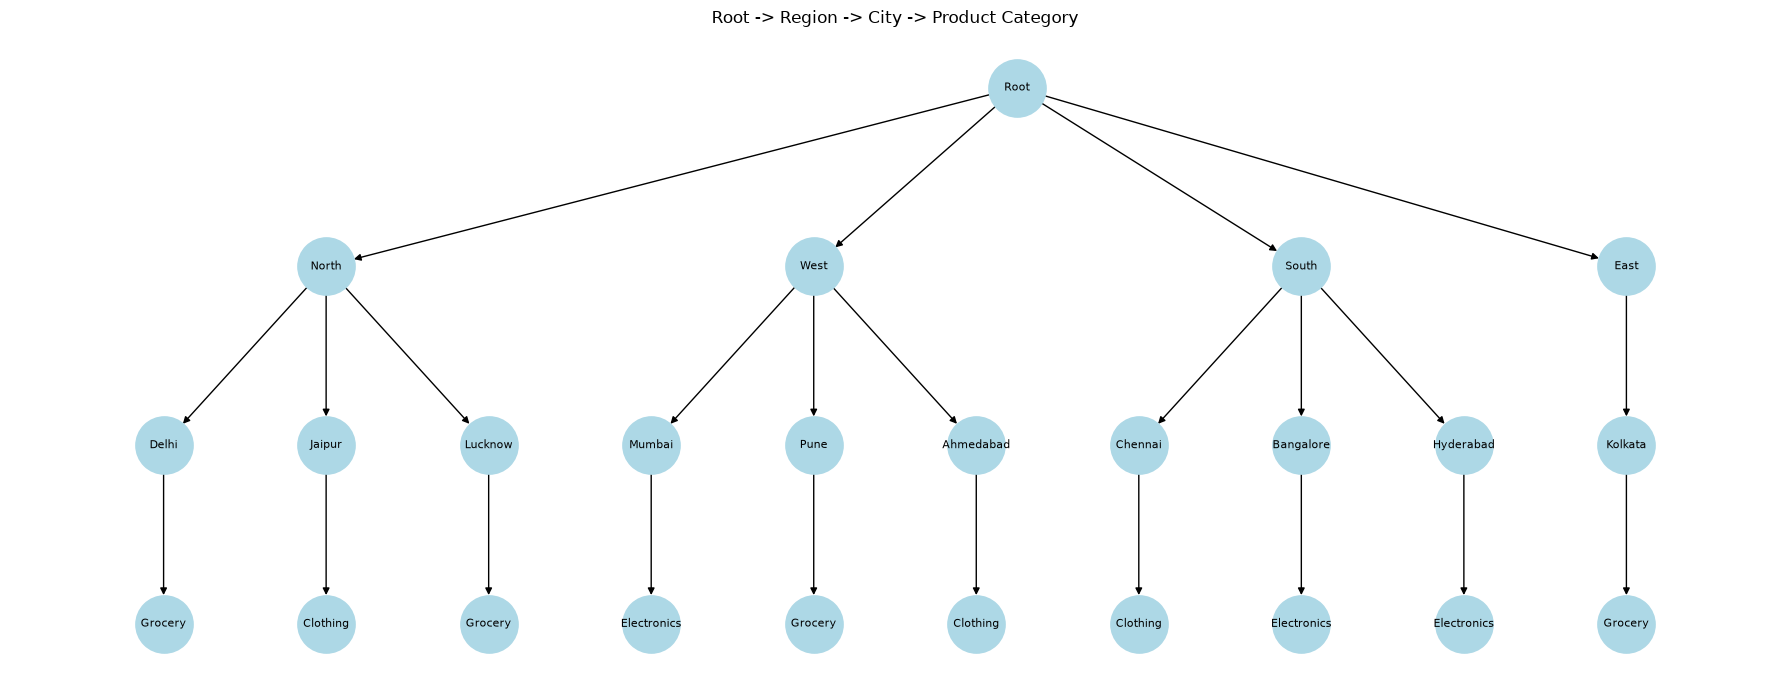

Saved question65_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_SalesData.csv")
print("Original dataset:")
display(df)

# Step 3: Create a directed tree with a single Root node.
tree = nx.DiGraph()
tree.add_node("Root")
labels = {"Root": "Root"}

# Step 4: Add each Root -> Region -> City -> Category path using unique node IDs.
for row in df.itertuples():
    region = f"Region:{row.Region}"
    city = f"{region}|City:{row.City}"
    category = f"{city}|Category:{row.Category}"
    tree.add_edges_from([("Root", region), (region, city), (city, category)])
    labels.update({region: row.Region, city: row.City, category: row.Category})


# Step 5: Assign positions that keep every child below its parent.
positions = {}
next_leaf = [0]
def position_subtree(node, depth=0):
    children = list(tree.successors(node))
    child_x = [position_subtree(child, depth + 1) for child in children]
    if child_x:
        x = float(np.mean(child_x))
    else:
        x = next_leaf[0]
        next_leaf[0] += 1
    positions[node] = (x, -depth)
    return x


# Step 6: Calculate the full tree layout.
position_subtree("Root")

# Step 7: Draw and label the hierarchy.
fig, ax = plt.subplots(figsize=(18, 7))
nx.draw_networkx(tree, positions, labels=labels, ax=ax, arrows=True,
                 node_size=1700, node_color="lightblue", font_size=8)
ax.set_title("Root -> Region -> City -> Product Category")
ax.axis("off")

# Step 8: Save all parent-child connections.
pd.DataFrame(tree.edges(), columns=["Parent", "Child"]).to_csv("hierarchy_edges.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question65_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question65_plot.png")


Interpretation / method

Path-qualified node IDs keep repeated categories under their own cities instead of accidentally merging branches.